# Tabular models for new donors: TabPFN and LightGBM on top of the shift and CellOT

**Question.** For a donor never seen in training, predict every stimulated quantile (stim × celltype × 13 functional
markers × quantile) from the donor's **Unstim** profile. Before this work, the best predictor was the 0.5/0.5 average of
paired CellOT and the feature-level shift ("CellOT + shift").

**What the tabular models predict.** The shift predicts `S = mean_train(S) + (U − mean_train(U))`: the average stim
effect added to the donor's own baseline. Each row of a table is one (donor, celltype, quantile, marker), and its
**target is what the shift misses**, `r = S − shift`. The final prediction is `shift + λ·r̂`. With λ = 1 (the full model
value), that is the model's own prediction of S. Training rows use leave-that-donor-out means, so they look like a new
donor.

**Protocol.** Learning-curve design: 5 repeats, 4 held-out test donors each, k = 3 / 5 / 8 / 15 training donors. All
features are refitted on the training donors only. Code: `lc/tab_features.py`, `lc/tab_predict.py` (round 1),
`lc/tab_v2.py` (rounds 2-3), `lc/tab_ens.py` (mixes), `lc/tab_compare.py` / `lc/ctx_score.py` (scores). Run log:
`work/lc/STATUS.md`.

**Scores.**
- *res_R2*: share of the shift's squared error that the model removes (0 = the shift, 1 = perfect).
- *MAE / MSE*: mean absolute / squared error of the predicted quantile (arcsinh units).
- *between_R2*: whether the predicted **differences between test donors** follow the real ones. Prediction and truth are
  centred across the test donors of each feature, so a shared offset does not count. The shift gives 0.57 here: that
  part of the donor differences is already present before stimulation.
- *skill* (round 1 only): `1 − |error| / |effect|`, median per repeat.
- Case sets: **floor** = every case whose effect for that donor is above 0.0273; **rule** = the any-quantile rule of
  `heldout/inclusion.py` at q50 / q75 / q90 (mean over the 19 donors of |stim − Unstim| > 0.1 at that quantile).
  From round 2 on, PI and IL33 are left out and only q50-q90 are scored.

In [1]:
import sys; sys.path.insert(0, "/scratch/users/bmerwan/atlas_heldout")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from scipy.stats import wilcoxon
from IPython.display import display
from lc.paths import WORK
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
TAB, EMB = WORK / "tab", WORK / "marker_embed"
# validated categorical order (dataviz reference palette), neutral reference ink, diverging blue - grey - red
S1, S2, S3, S4 = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, GRID, REF = "#0b0b0b", "#52514e", "#e6e5e0", "#8a8a85"
DIV = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRID,
                     "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False,
                     "axes.spines.right": False, "lines.linewidth": 2, "lines.markersize": 7, "font.size": 10,
                     "legend.frameon": False, "axes.titlesize": 11, "axes.titleweight": "bold"})

def endlabels(ax, items, gap=0.045):
    # direct labels at line ends, nudged apart so they never overlap (gap = fraction of the y range)
    lo, hi = ax.get_ylim(); d = gap * (hi - lo); items = sorted(items, key=lambda t: t[1]); ys = []
    for x, y, text in items:
        y2 = max(y, ys[-1] + d) if ys else y; ys.append(y2)
        ax.text(x + 0.35, y2, text, va="center", color=INK2, fontsize=9)

def rule(df): return df[df.set.str.startswith("rule")]

## 1. Round 1: feature layers, and the shuffled control

Features (round 1, `lc/tab_features.py`):
- **L0** (the feature itself): `u_dev = U − mean_train(U)`, `mu_u`, the average effect `eff`, `sd_u`, `noise_u`,
  `log_n`, plus `q`, `marker`, `celltype`.
- **L1** adds the donor's 65 Unstim values of the same celltype (13 markers × 5 quantiles, centred).
- **L2** adds whole-donor information: 28 log frequencies, 5 PCs of every celltype's Unstim medians, and 3 LDA donor axes.
- **Lperm** is a control: L1 and L2 shuffled across the training donors, so any gain from it would mean leakage.

Models: one LightGBM per (repeat, k, stim) pooling all celltypes; one TabPFN table per (repeat, k, stim, celltype).
TabPFN repeats 3-4 timed out (P100 GPUs), so TabPFN covers repeats 0-2 in this round.

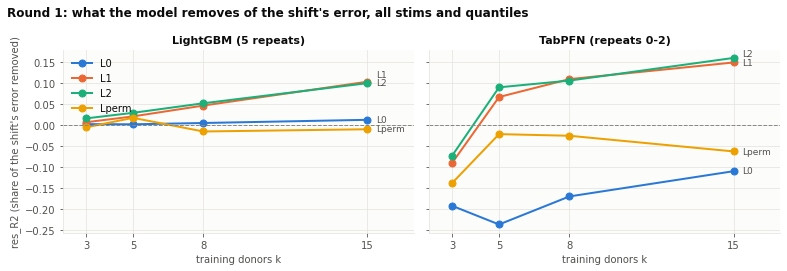

stim,GMCSF,IFNa,IL246,IL33,LPS,PI,TNFa
name,,,,,,,
lgbm_L0,0.018,0.030,0.011,0.030,-0.005,0.014,0.031
lgbm_L1,0.030,0.294,0.177,0.016,0.055,0.059,0.026
lgbm_L2,0.035,0.260,0.108,0.010,0.024,0.114,0.018
lgbm_L2perm,0.025,0.129,0.174,0.019,-0.000,-0.024,0.018
lgbm_Lperm,0.001,-0.013,-0.010,0.014,-0.002,-0.016,0.000


In [2]:
r_lgb = pd.read_csv(TAB / "res_v1_r0_1_2_3_4.csv"); r_pfn = pd.read_csv(TAB / "res_v1_r0_1_2.csv")
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, R, pre, title in [(axs[0], r_lgb, "lgbm", "LightGBM (5 repeats)"), (axs[1], r_pfn, "tabpfn", "TabPFN (repeats 0-2)")]:
    ends = []
    for L, col in zip(["L0", "L1", "L2", "Lperm"], [S1, S2, S3, S4]):
        g = R[R.name == f"{pre}_{L}"].sort_values("k")
        ax.plot(g.k, g.res_R2, "-o", color=col, label=L); ends.append((g.k.iloc[-1], g.res_R2.iloc[-1], L))
    ax.axhline(0, color=REF, lw=1, ls="--"); ax.set_xlim(2, 17); ax._ends = ends; ax.set_title(title); ax.set_xlabel("training donors k"); ax.set_xticks([3, 5, 8, 15])
axs[0].set_ylabel("res_R2 (share of the shift's error removed)"); axs[0].legend(loc="upper left")
for ax in axs: endlabels(ax, ax._ends)
fig.suptitle("Round 1: what the model removes of the shift's error, all stims and quantiles", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()
B = pd.read_csv(TAB / "res_by_stim_v1_r0_1_2_3_4.csv")
display(B[(B.k == 15) & B.name.str.startswith("lgbm_L")].pivot(index="name", columns="stim", values="res_R2").round(3))

**Reading.**
- The feature itself (L0) removes almost nothing with LightGBM (~1 %), and **hurts** with TabPFN (−0.11 to −0.24): on
  its own, TabPFN's correction from the row's own values is noise.
- The donor's own-celltype Unstim profile (L1) is what carries the signal: about 10 % of the shift's squared error with
  LightGBM and 15 % with TabPFN at k = 15. The gain grows with k and is not saturated at 15.
- Whole-donor information (L2) adds nothing on average on top of L1 (LightGBM .100 vs .104, TabPFN .160 vs .150).
- The shuffled control is ≤ 0, so the gain is real donor information, not leakage.
- The signal is concentrated in IFNa, IL246, LPS and PI, and is about zero for IL33 and GMCSF.

## 2. Shift + λ·r̂: keep the full model value (λ = 1)

λ scales the model's correction: λ = 0 is the plain shift, λ = 1 is the model's own prediction. Repeats 0-2, skill on
all cases, TabPFN L2 alone and averaged 0.5/0.5 with CellOT.

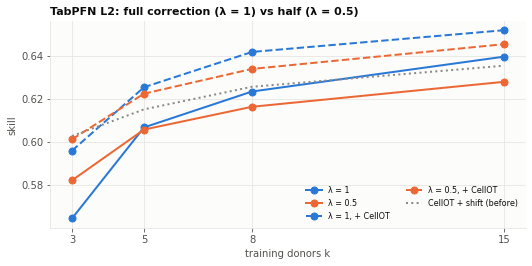

skill                      between_R2                     
k                  3      5      8      15         3      5      8      15
method                                                                    
ens             0.603  0.615  0.626  0.636      0.627  0.632  0.633  0.634
shift           0.588  0.592  0.601  0.607      0.593  0.593  0.593  0.593
tabpfn_L2       0.564  0.607  0.624  0.640      0.594  0.625  0.629  0.646
tabpfn_L2_ens   0.596  0.626  0.642  0.652      0.628  0.647  0.650  0.660
tabpfn_L2_h     0.582  0.606  0.616  0.628      0.594  0.614  0.616  0.626
tabpfn_L2_hens  0.601  0.622  0.634  0.646      0.628  0.641  0.642  0.648

In [3]:
C = pd.read_csv(TAB / "score_r0-2" / "curve.csv")
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for m, lab, col, ls in [("tabpfn_L2", "λ = 1", S1, "-"), ("tabpfn_L2_h", "λ = 0.5", S2, "-"),
                        ("tabpfn_L2_ens", "λ = 1, + CellOT", S1, "--"), ("tabpfn_L2_hens", "λ = 0.5, + CellOT", S2, "--")]:
    g = C[C.method == m].sort_values("k"); ax.plot(g.k, g.skill, ls, marker="o", color=col, label=lab)
g = C[C.method == "ens"].sort_values("k"); ax.plot(g.k, g.skill, ":", color=REF, label="CellOT + shift (before)")
ax.set_xticks([3, 5, 8, 15]); ax.set_xlabel("training donors k"); ax.set_ylabel("skill"); ax.legend(ncol=2, fontsize=8)
ax.set_title("TabPFN L2: full correction (λ = 1) vs half (λ = 0.5)", loc="left"); plt.tight_layout(); plt.show()
display(C[C.method.isin(["tabpfn_L2", "tabpfn_L2_h", "tabpfn_L2_ens", "tabpfn_L2_hens", "ens", "shift"])]
        .pivot(index="method", columns="k", values=["skill", "between_R2"]).round(3))

**Reading.** From k = 5 the full value (λ = 1) is as good or better, alone and with CellOT. Half the correction only helps
at k = 3, where the correction is mostly noise. Decision (2026-10-12): **always use the full model value**; only the
CellOT weight is tuned.

## 3. How much CellOT to mix in

`w · CellOT + (1 − w) · model` (paired CellOT). Below: rule cases, k = 15, all 5 repeats, round-2 TabPFN models. w = 0 is
the model alone and w = 1 is CellOT alone.

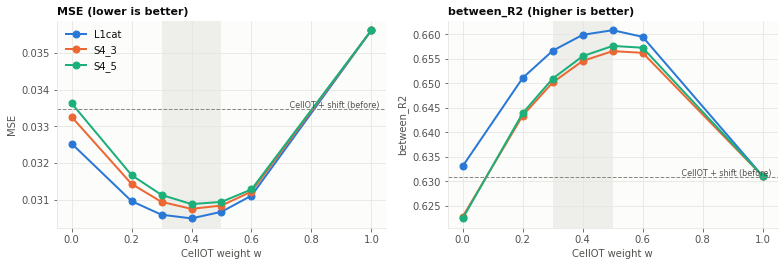

,corr,rmse_a,rmse_b,rmse_avg,w_a_best
pair,,,,,
CellOT vs shift,0.802,0.173,0.178,0.166,0.570
CellOT vs tabpfn_L2,0.799,0.173,0.163,0.159,0.352
CellOT vs lgbm_L2,0.814,0.173,0.165,0.161,0.384
tabpfn_L2 vs lgbm_L2,0.956,0.163,0.165,0.162,0.674
shift vs tabpfn_L2,0.957,0.178,0.163,0.168,0.000


In [4]:
W_ = pd.read_csv(TAB / "v2_wsweep_k15" / "metrics.csv"); Wr = rule(W_)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, met in zip(axs, ["MSE", "between_R2"]):
    cellot = Wr[Wr.method == "CellOT"][met].iloc[0]
    for L, col in zip(["L1cat", "S4_3", "S4_5"], [S1, S2, S3]):
        g = Wr[Wr.method.str.startswith(L + "_w")].copy(); g["w"] = g.method.str.split("_w").str[1].astype(float)
        g = pd.concat([g, pd.DataFrame({"w": [1.0], met: [cellot]})]).sort_values("w")
        ax.plot(g.w, g[met], "-o", color=col, label=L)
    ax.axhline(Wr[Wr.method == "CellOT+shift"][met].iloc[0], color=REF, ls="--", lw=1)
    ax.text(0.98, Wr[Wr.method == "CellOT+shift"][met].iloc[0], " CellOT + shift (before)", color=INK2, fontsize=8,
            ha="right", va="bottom", transform=ax.get_yaxis_transform())
    ax.axvspan(0.3, 0.5, color=GRID, alpha=0.6, lw=0); ax.set_xlabel("CellOT weight w"); ax.set_ylabel(met)
axs[0].legend(); axs[0].set_title("MSE (lower is better)", loc="left"); axs[1].set_title("between_R2 (higher is better)", loc="left")
plt.tight_layout(); plt.show()
E = pd.read_csv(TAB / "err_corr" / "by_k.csv")
display(E[E.k == 15].set_index("pair")[["corr", "rmse_a", "rmse_b", "rmse_avg", "w_a_best"]].round(3))

**Reading.** The optimum is flat between w = 0.3 and 0.5: **0.4 CellOT** is best on MSE and MAE, and between_R2 peaks at
0.5. The reason averaging helps: CellOT's errors correlate only ~0.80 with those of the shift-based models, while the
two tabular models (TabPFN and LightGBM) correlate ~0.96, so averaging TabPFN with LightGBM gains nothing. CellOT brings
the shape of the response (most in the lower tail and for IL246 / IFNa / PI); the tabular correction brings the
donor-specific level. The table's `w_a_best` is the in-sample best weight on the first method of each pair.

## 4. Which features LightGBM uses (SHAP, round 1, L2, k = 15)

Exact TreeSHAP on the test donors' rows. Groups sum their features' SHAP per row; the L1 block is split by its relation
to the row being predicted. SHAP shows **use**, not usefulness: the ablations below test the gains.

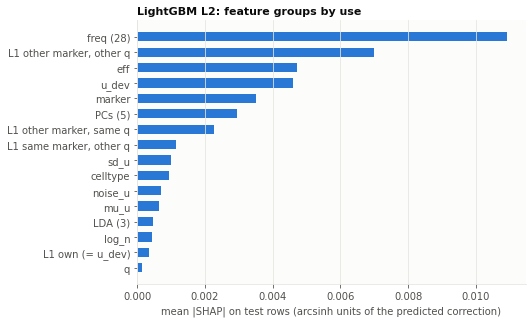

In [5]:
S = pd.read_csv(TAB / "shap" / "by_group.csv")
g = S[S.group != "TOTAL (prediction)"].groupby("group").mean_abs.mean().sort_values()
fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.barh(g.index, g.values, color=S1, height=0.6); ax.grid(axis="y", visible=False)
ax.set_xlabel("mean |SHAP| on test rows (arcsinh units of the predicted correction)")
ax.set_title("LightGBM L2: feature groups by use", loc="left"); plt.tight_layout(); plt.show()

**Reading.** The average effect (`eff`), the donor's own deviation (`u_dev`) and `marker` lead. Within L1 the model uses
the **other** markers of the same celltype (its own value is already `u_dev`). With L2, the frequencies take the largest
share and L1's share halves, without any gain in accuracy: the model trades one block for the other. The LDA axes and
`log_n` are barely used.

## 5. Round 2: building the feature set step by step (TabPFN)

From here: PI and IL33 left out, only q50 / q75 / q90 predicted, `marker` passed to TabPFN as **categorical**, `log_n`
dropped, all 5 repeats. Steps (`lc/tab_v2.py`):

| layer | features |
|---|---|
| S0 | u_dev, mu_u, eff, sd_u, noise_u, q, marker |
| S1_5 / S1_7 | + 5 / 7 PCs of the own-celltype profile |
| S2 | + 3 PCs of the 28 log frequencies |
| S3 | + HV/PV |
| S4_3 / S4_5 / S4_7 | + 3 / 5 PCs of the whole-blood profile (28 × 65); S4_7 uses 7 own-profile PCs |
| L1cat | S0 + the raw 65 own-celltype columns |
| S4perm | S4_5 with every donor block shuffled across training donors (control) |

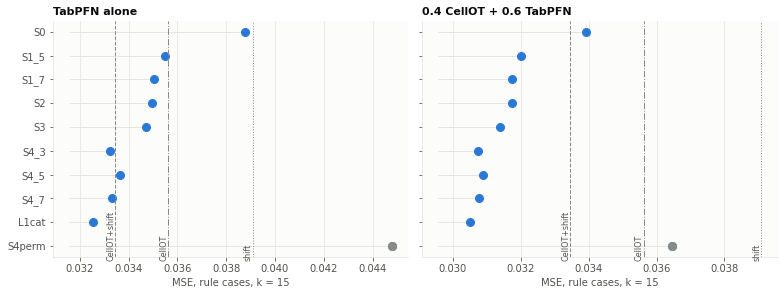

,MAE,MSE,between_R2
method,,,
S0,0.1292,0.0388,0.5768
S1_5,0.1242,0.0355,0.6012
S1_7,0.1234,0.0350,0.5997
S2,0.1225,0.0350,0.6032
S3,0.1215,0.0347,0.6031
S4_3,0.1191,0.0333,0.6228
S4_5,0.1191,0.0336,0.6225
S4_7,0.1190,0.0333,0.6234
L1cat,0.1192,0.0325,0.6331


In [6]:
V = rule(pd.read_csv(TAB / "v2_compare_k15" / "metrics.csv")).set_index("method")
order = ["S0", "S1_5", "S1_7", "S2", "S3", "S4_3", "S4_5", "S4_7", "L1cat", "S4perm"]
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, pref, title in [(axs[0], "", "TabPFN alone"), (axs[1], "0.4CellOT+0.6", "0.4 CellOT + 0.6 TabPFN")]:
    y = np.arange(len(order))[::-1]; x = [V.loc[pref + L, "MSE"] for L in order]
    ax.hlines(y, min(x) * 0.97, x, color=GRID, lw=1)
    ax.plot(x, y, "o", color=S1, ms=8)
    ax.plot(x[-1], y[-1], "o", color=REF, ms=8)
    for ref, ls in [("shift", ":"), ("CellOT", "-."), ("CellOT+shift", "--")]:
        ax.axvline(V.loc[ref, "MSE"], color=REF, ls=ls, lw=1)
        ax.text(V.loc[ref, "MSE"], -0.6, ref, rotation=90, fontsize=8, color=INK2, ha="right", va="bottom")
    ax.set_title(title, loc="left"); ax.set_xlabel("MSE, rule cases, k = 15"); ax.grid(axis="y", visible=False)
axs[0].set_yticks(np.arange(len(order))[::-1]); axs[0].set_yticklabels(order)
plt.tight_layout(); plt.show()
display(V.loc[order + ["shift", "CellOT", "CellOT+shift"], ["MAE", "MSE", "between_R2"]].round(4))

In [7]:
D = rule(pd.read_pickle(TAB / "v2_steps_cases" / "cases.pkl"))
ms = ["shift", "CellOT", "S0", "S1_5", "S2", "S3", "S4_5", "L1cat"]
print("MSE alone by k (rule cases)")
display(pd.DataFrame({k: {m: ((g[m] - g.true) ** 2).mean() for m in ms} for k, g in D.groupby("k")}).round(4))
def paired(g, a, b):
    e = g.assign(x=(g[a] - g.true).abs(), y=(g[b] - g.true).abs()).groupby(["repeat", "stim", "celltype", "donor"])[["x", "y"]].mean()
    return 100 * ((g[a] - g.true).abs() < (g[b] - g.true).abs()).mean(), wilcoxon(e.x, e.y).pvalue
print("HV/PV (S3 vs S2): % of cases closer with HV/PV, Wilcoxon p, MSE change")
for k, g in D.groupby("k"):
    c, p = paired(g, "S3", "S2"); m2, m3 = ((g.S2 - g.true) ** 2).mean(), ((g.S3 - g.true) ** 2).mean()
    print(f"  k = {k:2d}: {c:4.1f} %  p = {p:.0e}  MSE {m2:.4f} -> {m3:.4f} ({100 * (m3 / m2 - 1):+.1f} %)")

MSE alone by k (rule cases)


,3,5,8,15
shift,0.0483,0.0459,0.0417,0.0391
CellOT,0.0517,0.0460,0.0400,0.0356
S0,0.0564,0.0477,0.0418,0.0388
S1_5,0.0659,0.0442,0.0406,0.0355
S2,0.0623,0.0431,0.0393,0.0350
S3,0.0588,0.0424,0.0389,0.0347
S4_5,0.0566,0.0412,0.0391,0.0336
L1cat,0.0514,0.0425,0.0394,0.0325


HV/PV (S3 vs S2): % of cases closer with HV/PV, Wilcoxon p, MSE change
  k =  3: 35.1 %  p = 2e-27  MSE 0.0623 -> 0.0588 (-5.7 %)
  k =  5: 50.2 %  p = 2e-01  MSE 0.0431 -> 0.0424 (-1.8 %)
  k =  8: 50.3 %  p = 1e-01  MSE 0.0393 -> 0.0389 (-0.8 %)
  k = 15: 51.4 %  p = 3e-06  MSE 0.0350 -> 0.0347 (-0.6 %)


**Reading.**
- S0 alone is the shift (it removes ~1 % of its error). S0's mix with CellOT equals CellOT + shift only because CellOT
  carries it.
- The own-celltype profile is the big step. Its 5-7 PCs (S1) lose clearly against the **raw 65 columns** (L1cat):
  unsupervised PCs keep the directions where donors vary most, not the ones that predict the response.
- Frequency PCs, HV/PV and whole-blood PCs each add a little on top of the PCs (S4 ≈ L1cat), but never beat L1cat.
- HV/PV is a small but real gain at k = 15 only (−0.9 % MSE, p ≈ 3e-6), mixed by stim.
- The shuffled control is worse than the shift: no leakage.

## 6. Round 3: raw own profile + whole-donor blocks, both models

Same rows and features for both models; LightGBM pools all celltypes with `celltype` categorical (`--model lgbm`).
- **L1F** = L1cat + 28 raw log frequencies; **L1fpc** = + 3 frequency PCs.
- **L1all_pc** = + frequency PCs, HV/PV and 3 whole-blood PCs; **L1all_raw** = the same with the 28 raw frequencies.
- **L1cat_mx / L1cat_mxc**: marker axes, see section 7.

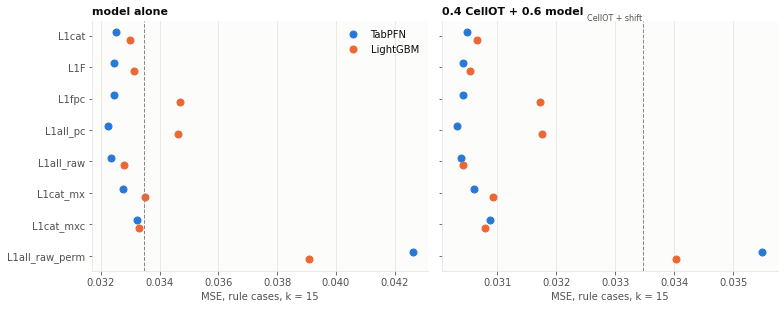

MAE                                           MSE                                      
model              lgb                    pfn                    lgb                    pfn               
version          alone mix 0.4 CellOT   alone mix 0.4 CellOT   alone mix 0.4 CellOT   alone mix 0.4 CellOT
layer                                                                                                     
L1F             0.1204         0.1156  0.1185         0.1150  0.0331         0.0305  0.0324         0.0304
L1all_pc        0.1221         0.1173  0.1185         0.1151  0.0346         0.0318  0.0322         0.0303
L1all_raw       0.1196         0.1152  0.1186         0.1151  0.0328         0.0304  0.0324         0.0304
L1all_raw_perm  0.1293         0.1212  0.1363         0.1246  0.0391         0.0340  0.0426         0.0355
L1cat           0.1189         0.1152  0.1192         0.1154  0.0330         0.0307  0.0325         0.0305
L1cat_mx        0.1199         0.1157  0.1196         0.1156  0.0335         0.0309  0.0328         0.0306
L1cat_mxc       0.1194         0.1155  0.1208         0.1163  0.0333         0.0308  0.0332         0.0309
L1fpc           0.1227         0.1174  0.1190         0.1152  0.0347         0.0317  0.0324         0.0304

paired vs the same model's L1cat (alone): % of cases closer, Wilcoxon p


,pct_a_closer,p_wilcoxon
a,,
shift,44.9610,0.0000
shift,44.2113,0.0000
CellOT,48.1745,0.0001
CellOT,48.1243,0.0002
CellOT+shift,49.2196,0.0126
CellOT+shift,49.3646,0.2398
pfn_L1cat_mx,49.4537,0.0293
pfn_L1cat_mx,49.0134,0.6429
lgb_L1cat_mx,50.0780,0.0491


In [8]:
X = rule(pd.read_csv(TAB / "v3all_compare_k15" / "metrics.csv")).set_index("method")
lay = ["L1cat", "L1F", "L1fpc", "L1all_pc", "L1all_raw", "L1cat_mx", "L1cat_mxc", "L1all_raw_perm"]
fig, axs = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
for ax, pre, title in [(axs[0], "", "model alone"), (axs[1], "mix_", "0.4 CellOT + 0.6 model")]:
    y = np.arange(len(lay))[::-1]
    for m, col, dy, lab in [("pfn", S1, 0.12, "TabPFN"), ("lgb", S2, -0.12, "LightGBM")]:
        key = (lambda L: f"mix_{m}_{L}") if pre else (lambda L: f"{m}_{L}")
        x = [X.loc[key(L), "MSE"] if key(L) in X.index else np.nan for L in lay]
        ax.plot(x, y + dy, "o", color=col, label=lab)
    ax.axvline(X.loc["CellOT+shift", "MSE"], color=REF, ls="--", lw=1)
    ax.set_title(title, loc="left"); ax.set_xlabel("MSE, rule cases, k = 15"); ax.grid(axis="y", visible=False)
axs[0].set_yticks(np.arange(len(lay))[::-1]); axs[0].set_yticklabels(lay); axs[0].legend(loc="upper right")
axs[1].text(X.loc["CellOT+shift", "MSE"], len(lay) - 0.5, "CellOT + shift", fontsize=8, color=INK2, ha="right")
plt.tight_layout(); plt.show()
cols = []
for m in ["pfn", "lgb"]:
    for L in lay:
        for k2, nm in [(f"{m}_{L}", "alone"), (f"mix_{m}_{L}", "mix 0.4 CellOT")]:
            if k2 in X.index: cols.append({"model": m, "layer": L, "version": nm, **X.loc[k2, ["MAE", "MSE", "between_R2"]].to_dict()})
display(pd.DataFrame(cols).pivot_table(index=["layer"], columns=["model", "version"], values=["MAE", "MSE"]).round(4))
P = rule(pd.read_csv(TAB / "v3all_compare_k15" / "paired.csv"))
print("paired vs the same model's L1cat (alone): % of cases closer, Wilcoxon p")
display(P[P.b.isin(["pfn_L1cat", "lgb_L1cat"]) & (P.a.str[4:] != "L1cat") & ~P.a.str.startswith("mix_")]
        .set_index("a")[["pct_a_closer", "p_wilcoxon"]].round(4))

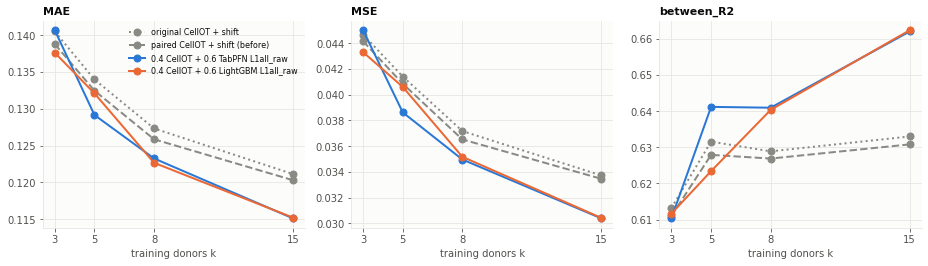

MAE                             MSE                         between_R2                        
k                        3       5       8       15      3       5       8       15         3       5       8       15
method                                                                                                                
CellOT_orig          0.1515  0.1426  0.1339  0.1261  0.0529  0.0473  0.0417  0.0365     0.5813  0.6173  0.6197  0.6336
CellOT_orig+shift    0.1405  0.1340  0.1273  0.1211  0.0447  0.0414  0.0372  0.0337     0.6132  0.6316  0.6289  0.6330
CellOT_paired        0.1475  0.1392  0.1301  0.1234  0.0517  0.0460  0.0400  0.0356     0.5741  0.6123  0.6180  0.6311
CellOT_paired+shift  0.1388  0.1325  0.1259  0.1203  0.0442  0.0408  0.0365  0.0335     0.6110  0.6279  0.6269  0.6308
lgb_L1all_raw        0.1428  0.1388  0.1275  0.1196  0.0468  0.0449  0.0380  0.0328     0.5766  0.5723  0.6102  0.6295
mix_lgb_L1all_raw    0.1376  0.1321  0.1227  0.1152  0.0433  0.0406  0.0352  0.0304     0.6116  0.6234  0.6404  0.6624
mix_pfn_L1all_raw    0.1407  0.1292  0.1233  0.1151  0.0450  0.0386  0.0350  0.0304     0.6103  0.6412  0.6410  0.6621
pfn_L1all_raw        0.1499  0.1343  0.1287  0.1186  0.0508  0.0415  0.0379  0.0324     0.5692  0.6048  0.6068  0.6377
shift                0.1450  0.1402  0.1342  0.1292  0.0483  0.0459  0.0417  0.0391     0.5677  0.5677  0.5677  0.5677

In [9]:
O = rule(pd.read_csv(TAB / "v3_orig_cellot" / "metrics_with_orig_ens.csv"))
show = [("CellOT_orig+shift", "original CellOT + shift", REF, ":"), ("CellOT_paired+shift", "paired CellOT + shift (before)", REF, "--"),
        ("mix_pfn_L1all_raw", "0.4 CellOT + 0.6 TabPFN L1all_raw", S1, "-"), ("mix_lgb_L1all_raw", "0.4 CellOT + 0.6 LightGBM L1all_raw", S2, "-")]
fig, axs = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, met in zip(axs, ["MAE", "MSE", "between_R2"]):
    for m, lab, col, ls in show:
        g = O[O.method == m].sort_values("k"); ax.plot(g.k, g[met], ls, marker="o", color=col, label=lab)
    ax.set_xticks([3, 5, 8, 15]); ax.set_xlabel("training donors k"); ax.set_title(met, loc="left")
axs[0].legend(fontsize=8); plt.tight_layout(); plt.show()
display(O.pivot(index="method", columns="k", values=["MAE", "MSE", "between_R2"]).round(4))

**Reading.**
- Every real layer of both models lands at MSE .0303-.0309 once mixed with 0.4 CellOT (CellOT + shift: .0335).
- For TabPFN, whole-donor blocks on top of the raw profile are neutral, raw frequencies and frequency PCs alike.
- For LightGBM, frequency PCs hurt and raw frequencies are neutral.
- By stim, the frequency blocks help LPS and GMCSF but hurt IL246 and TNFa, which is why the overall effect is ~0.
- Best overall: **0.4 CellOT + 0.6 × L1all_raw**. MAE goes from .1203 to .1151, MSE −9 %, and between_R2 from .631
  to .662. That is about 22 % of the donor differences that the shift cannot explain.
- Learning curve: LightGBM mixes are the only ones to beat CellOT + shift at k = 3. TabPFN mixes are best at k = 5-8,
  and the two models tie at k = 15.
- The original (unpaired) CellOT is slightly worse than the paired one alone; averaged with the shift, the two are
  within .001.

## 7. Telling the model which markers behave alike: ESM2 did not work, data-driven axes did not help

**ESM2.** Protein embeddings (esm2_t33_650M, mean over residues; pERK = ERK1/ERK2 mean, pSTAT5 = STAT5A/B mean) were
compared with two response similarities over the 78 marker pairs:
- **trajectory**: per celltype, correlation of the mean stim effects across stims × quantiles;
- **residual**: correlation across donors of what the shift misses.

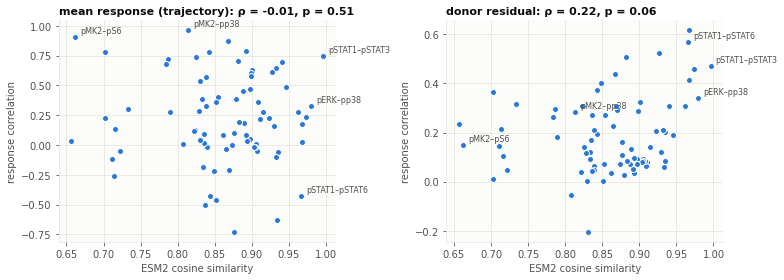

In [10]:
Pm = pd.read_csv(EMB / "pairs.csv"); Sm = pd.read_csv(EMB / "summary.csv")
fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
for ax, col, title in [(axs[0], "trajectory_r", "mean response (trajectory)"), (axs[1], "residual_r", "donor residual")]:
    ax.plot(Pm.esm2_cos, Pm[col], "o", color=S1, ms=6, mec="#fcfcfb", mew=1)
    for a, b in [("pMK2", "pp38"), ("pMK2", "pS6"), ("pSTAT1", "pSTAT6"), ("pSTAT1", "pSTAT3"), ("pERK", "pp38")]:
        r = Pm[((Pm.m1 == a) & (Pm.m2 == b)) | ((Pm.m1 == b) & (Pm.m2 == a))].iloc[0]
        ax.annotate(f"{a}–{b}", (r.esm2_cos, r[col]), xytext=(5, 4), textcoords="offset points", fontsize=8, color=INK2)
    rho = Sm.set_index("response").loc[col.split("_")[0], ["spearman_vs_esm2", "mantel_p"]]
    ax.set_title(f"{title}: ρ = {rho.spearman_vs_esm2:.2f}, p = {rho.mantel_p:.2f}", loc="left")
    ax.set_xlabel("ESM2 cosine similarity"); ax.set_ylabel("response correlation")
plt.tight_layout(); plt.show()

**Reading.** ESM2 encodes sequence families (the STATs together, ERK with p38), not signalling. Its correlation with the
mean response is ~0. For example, pMK2-pp38 respond almost identically (r .96: MK2 is phosphorylated by p38), yet their
ESM2 similarity is below average. A 1D projection of ESM2 keeps nothing of the response.

**Data-driven axes instead.** 3 MDS coordinates per marker were taken from the trajectory correlation, fitted on the
training donors of each (repeat, k). They do place pMK2 next to pp38 and pS6, and pSTAT1 far from pSTAT6. Used in
TabPFN / LightGBM (round 3, section 6 tables):
- **L1cat_mx** (axes instead of the categorical marker) is slightly worse: TabPFN .0328 vs .0325, LightGBM .0335
  vs .0330.
- **L1cat_mxc** (marker + axes) is no better.

The models learn marker identity directly; shared marker structure is not what drives donor-specific deviations.

## 8. Lineage-group tables: pooling similar celltypes into one TabPFN table

One table per (stim, group) with `celltype` categorical, instead of one per celltype. Groups were chosen by the
correlation of their effect profiles (.89-1.00):
- **CD4mem**: CD4Tcm, CD4Tcm_CCR2pos, CD4Tem, CD4Tem_CCR2pos
- **CD8eff**: CD8Tem, CD8Tem_CCR2pos, CD8Teff, CD8Tcells_Th1
- **NK16**: CD56lo NK, NK CD11c−, NK CD11c+
- **Mono**: cMCs, intMCs, ncMCs

Feature sets G_S0, G_S1_5 and G_S4_5 are compared with the per-celltype S0, S1_5 and S4_5, TabPFN alone, rule cases.
Caveat: the own-profile PCs are fitted per celltype, so "PC1" means something different in each celltype of a group.

Colour = % MSE change from grouping: **blue = grouping better**, red = worse. Stars mark p < .05 (*) and p < .01 (**),
Wilcoxon over (repeat, stim, donor), per celltype.

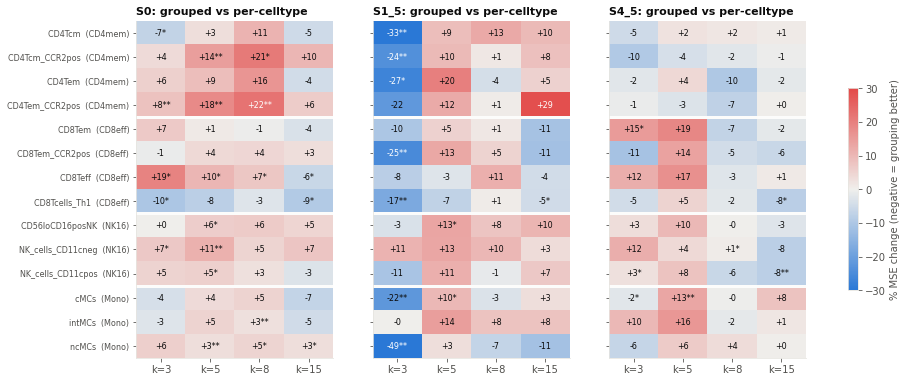

In [11]:
G = {"CD4mem": ["CD4Tcm", "CD4Tcm_CCR2pos", "CD4Tem", "CD4Tem_CCR2pos"],
     "CD8eff": ["CD8Tem", "CD8Tem_CCR2pos", "CD8Teff", "CD8Tcells_Th1"],
     "NK16": ["CD56loCD16posNK", "NK_cells_CD11cneg", "NK_cells_CD11cpos"], "Mono": ["cMCs", "intMCs", "ncMCs"]}
ORDER = [c for g in G.values() for c in g]; GROUP = {c: g for g, cs in G.items() for c in cs}
Q = rule(pd.read_pickle(TAB / "v2_groups_cases" / "cases.pkl"))
def change(g, L, by):
    a, b = f"grp_{L}", f"ct_{L}"
    ma, mb = ((g[a] - g.true) ** 2).mean(), ((g[b] - g.true) ** 2).mean()
    e = g.assign(x=(g[a] - g.true).abs(), y=(g[b] - g.true).abs()).groupby(by)[["x", "y"]].mean()
    p = wilcoxon(e.x, e.y).pvalue if len(e) > 5 and (e.x != e.y).any() else np.nan
    return pd.Series({"chg": 100 * (ma / mb - 1), "p": p})

def heat(ax, M, Pv, title, xlabels):
    vmax = 30; im = ax.imshow(M.values.astype(float), cmap=DIV, norm=TwoSlopeNorm(0, -vmax, vmax), aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M.values[i, j]
            if np.isnan(v): continue
            p = Pv.values[i, j]; star = "**" if p < 0.01 else ("*" if p < 0.05 else "")
            ax.text(j, i, f"{v:+.0f}{star}", ha="center", va="center", fontsize=8, color=INK if abs(v) < 22 else "#ffffff")
    ax.set_xticks(range(M.shape[1])); ax.set_xticklabels(xlabels); ax.set_yticks(range(M.shape[0]))
    ax.set_yticklabels([f"{c}  ({GROUP[c]})" for c in M.index], fontsize=8); ax.grid(False); ax.set_title(title, loc="left")
    for b in np.cumsum([len(v) for v in G.values()])[:-1]: ax.axhline(b - 0.5, color="#fcfcfb", lw=3)
    return im

fig, axs = plt.subplots(1, 3, figsize=(15, 6.2), sharey=True)
for ax, L in zip(axs, ["S0", "S1_5", "S4_5"]):
    R = Q.groupby(["celltype", "k"]).apply(lambda g: change(g, L, ["repeat", "stim", "donor"]), include_groups=False)
    M = R["chg"].unstack().reindex(ORDER); Pv = R["p"].unstack().reindex(ORDER)
    im = heat(ax, M, Pv, f"{L}: grouped vs per-celltype", [f"k={k}" for k in M.columns])
fig.colorbar(im, ax=axs, shrink=0.6, label="% MSE change (negative = grouping better)")
plt.show()

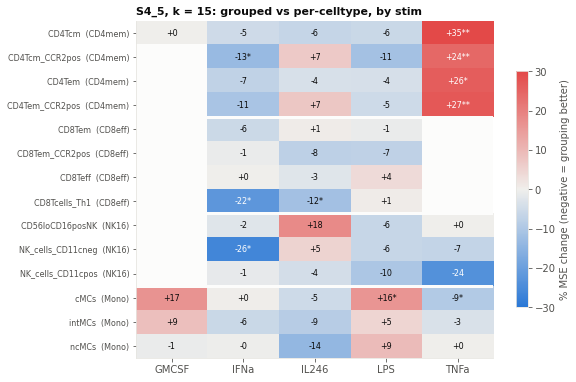

per-celltype MSE (S4_5 alone, k = 15):


,MSE
celltype,
CD4Tcm,0.0282
CD4Tcm_CCR2pos,0.0271
CD4Tem,0.0360
CD4Tem_CCR2pos,0.0290
CD8Tem,0.0232
CD8Tem_CCR2pos,0.0283
CD8Teff,0.0303
CD8Tcells_Th1,0.0596
CD56loCD16posNK,0.0239


In [12]:
fig, ax = plt.subplots(figsize=(8, 6.2))
R = Q[Q.k == 15].groupby(["celltype", "stim"]).apply(lambda g: change(g, "S4_5", ["repeat", "donor"]), include_groups=False)
M = R["chg"].unstack().reindex(ORDER); Pv = R["p"].unstack().reindex(ORDER)
im = heat(ax, M, Pv, "S4_5, k = 15: grouped vs per-celltype, by stim", list(M.columns))
fig.colorbar(im, ax=ax, shrink=0.7, label="% MSE change (negative = grouping better)"); plt.show()
print("per-celltype MSE (S4_5 alone, k = 15):")
display(Q[Q.k == 15].groupby("celltype").apply(lambda g: ((g.ct_S4_5 - g.true) ** 2).mean(), include_groups=False).reindex(ORDER).round(4).to_frame("MSE"))

**Reading.**
- **Who gains:** celltypes that are hard to predict on their own borrow from their relatives.
  - CD8Tcells_Th1 has by far the largest error alone and gains with every feature set at k = 15.
  - NK CD11c+ gains −8 % (p < .01).
- **IFNa** improves in almost every celltype at k = 15: the JAK-STAT response is shared within these lineages.
- **At k = 3 with weak features (S1_5)**, grouping helps almost everywhere (−17 to −49 %): pooling multiplies the
  training rows when donors are scarce.
- **Who loses:**
  - **TNFa in all four CD4 memory subsets** (+24 to +35 %).
  - **cMCs with LPS and GMCSF** (+16-17 %): classical monocytes respond differently from intermediate and
    non-classical ones.
  - At **k = 5**, grouping is worse almost everywhere.
- **Use selectively**: k = 3, IFNa, and the tight CD8/NK groups. Before trying it more widely, fix the per-celltype PC
  design: use the raw own profile, or one PCA shared across the group.

## 9. Which CellOT to mix with: covariate CellOTs add on top of the tabular model

Everything above mixes the tabular model with the **paired, context-free CellOT** (`cond_train --ctx none`). Earlier
CellOT experiments had also trained versions that receive a donor covariate. Their predictions exist at k = 15 for all
5 repeats, so each was scored alone, averaged with the shift, and mixed 0.4 / 0.6 with TabPFN or LightGBM L1all_raw.

Setup: rule cases, PI and IL33 left out, q50-q90; each donor counted once; Wilcoxon over the 14 donors against the
same use of the paired CellOT. Versions:
- `cluster_K4_stable`: phenotype subclusters (cells paired within subcluster);
- `pcblood_wd1`: own + 4 dominant celltypes' Unstim medians and frequencies → 3 PCs;
- `pcb_film` / `pcb_affine` / `pcb_trans`: other conditionings of the pcblood covariate;
- `pc_wd1`: PCs of the own celltype;
- `ft_pre` / `ft_rand`: ImmuneFM-pretrained / random-init encoder;
- `lda3`: LDA donor axes;
- `orig`: the original unpaired CellOT.

The `dnorm` runs are left out: their predictions are stored in a donor-normalised space. Results:
`work/lc/tab/cellot_variants_k15/variants_mix.csv`.

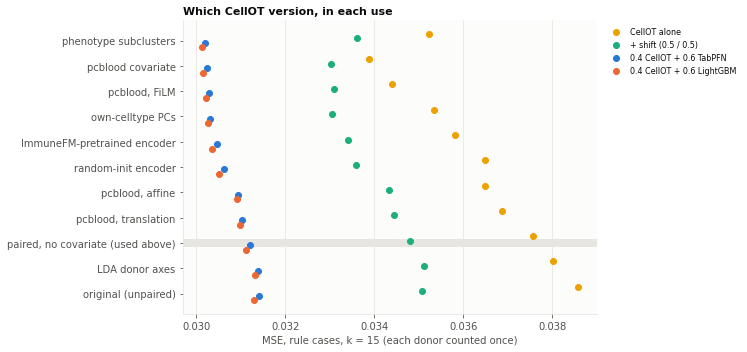

MAE_donor                                                                      MSE_donor                                                                
use                               +shift 0.5/0.5 0.4 + 0.6 LightGBM L1all_raw 0.4 + 0.6 TabPFN L1all_raw   alone +shift 0.5/0.5 0.4 + 0.6 LightGBM L1all_raw 0.4 + 0.6 TabPFN L1all_raw   alone
version                                                                                                                                                                                        
phenotype subclusters                     0.1208                       0.1143                     0.1146  0.1231         0.0336                       0.0301                     0.0302  0.0352
pcblood covariate                         0.1194                       0.1138                     0.1141  0.1204         0.0330                       0.0302                     0.0302  0.0339
pcblood, FiLM                             0.1193                       0.1137                     0.1140  0.1207         0.0331                       0.0302                     0.0303  0.0344
own-celltype PCs                          0.1193                       0.1139                     0.1142  0.1218         0.0330                       0.0303                     0.0303  0.0353
ImmuneFM-pretrained encoder               0.1201                       0.1143                     0.1146  0.1231         0.0334                       0.0304                     0.0305  0.0358
random-init encoder                       0.1202                       0.1144                     0.1147  0.1239         0.0336                       0.0305                     0.0306  0.0365
pcblood, affine                           0.1218                       0.1155                     0.1157  0.1247         0.0343                       0.0309                     0.0309  0.0365
pcblood, translation                      0.1218                       0.1154                     0.1156  0.1249         0.0345                       0.0310                     0.0310  0.0369
paired, no covariate (used above)         0.1225                       0.1159                     0.1161  0.1261         0.0348                       0.0311                     0.0312  0.0376
LDA donor axes                            0.1234                       0.1165                     0.1167  0.1277         0.0351                       0.0313                     0.0314  0.0380
original (unpaired)                       0.1236                       0.1167                     0.1170  0.1293         0.0351                       0.0313                     0.0314  0.0386

donors_better                                               vs_none_p                           
use                         0.4 + 0.6 LightGBM L1all_raw 0.4 + 0.6 TabPFN L1all_raw 0.4 + 0.6 LightGBM L1all_raw 0.4 + 0.6 TabPFN L1all_raw
version                                                                                                                                    
ImmuneFM-pretrained encoder                         11.0                       11.0                        0.068                      0.078
LDA donor axes                                       6.0                        6.0                        0.670                      0.761
original (unpaired)                                  5.0                        4.0                        0.268                      0.268
own-celltype PCs                                     9.0                        9.0                        0.153                      0.135
pcblood covariate                                   11.0                       10.0                        0.025                      0.030
pcblood, FiLM                                       10.0                       10.0                        0.058                      0.042
pcblood, affine                                      9.0                        9.0                        0.194                      0.104
pcblood, translation                                 8.0                        8.0                        0.326                      0.326
phenotype subclusters                               14.0                       14.0                        0.000                      0.000
random-init encoder                                  9.0                        7.0                        0.296                      0.358

In [13]:
VM = pd.read_csv(TAB / "cellot_variants_k15" / "variants_mix.csv"); VM = VM[~VM.cellot.str.startswith("dnorm")]
names = {"none": "paired, no covariate (used above)", "orig": "original (unpaired)", "cluster_K4_stable": "phenotype subclusters",
         "pcblood_wd1": "pcblood covariate", "pcb_film_wd1": "pcblood, FiLM", "pc_wd1": "own-celltype PCs",
         "ft_pre_wd1": "ImmuneFM-pretrained encoder", "ft_rand_wd1": "random-init encoder", "pcb_affine_wd1": "pcblood, affine",
         "pcb_trans_wd1": "pcblood, translation", "lda3_wd1": "LDA donor axes"}
uses = [("alone", "CellOT alone", S4), ("+shift 0.5/0.5", "+ shift (0.5 / 0.5)", S3),
        ("0.4 + 0.6 TabPFN L1all_raw", "0.4 CellOT + 0.6 TabPFN", S1), ("0.4 + 0.6 LightGBM L1all_raw", "0.4 CellOT + 0.6 LightGBM", S2)]
order = VM[VM.use == "0.4 + 0.6 TabPFN L1all_raw"].sort_values("MSE_donor", ascending=False).cellot.tolist()
fig, ax = plt.subplots(figsize=(10.5, 5))
y = np.arange(len(order))
for (u, lab, col), dy in zip(uses, [0.27, 0.09, -0.09, -0.27]):
    g = VM[VM.use == u].set_index("cellot").reindex(order)
    ax.plot(g.MSE_donor, y + dy, "o", color=col, label=lab, ms=6)
ax.set_yticks(y); ax.set_yticklabels([names[c] for c in order]); ax.grid(axis="y", visible=False)
ax.axhline(order.index("none"), color=GRID, lw=8, zorder=0)
ax.set_xlabel("MSE, rule cases, k = 15 (each donor counted once)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
ax.set_title("Which CellOT version, in each use", loc="left")
plt.tight_layout(); plt.show()
T9 = VM.assign(version=VM.cellot.map(names)).pivot_table(index="version", columns="use", values=["MAE_donor", "MSE_donor"])
display(T9.reindex([names[c] for c in order[::-1]]).round(4))
display(VM[VM.use.str.startswith("0.4")].assign(version=VM.cellot.map(names))
        .pivot_table(index="version", columns="use", values=["donors_better", "vs_none_p"]).round(3))

**Reading.**
- On this scoring, several covariate CellOTs are better than the paired, context-free one. pcblood is −10 % MSE
  alone. Earlier skill-based comparisons had called these ties.
- **The gain survives the mix with the tabular model.** With 0.4 CellOT + 0.6 TabPFN L1all_raw, MSE goes from .0312
  (paired CellOT) to .0302 (−3 %):
  - phenotype subclusters: better for **all 14 donors** (p = 1e-4);
  - pcblood: 10 / 14 donors (p = .03);
  - pcblood with FiLM: the best MAE (.1140).

  So the covariate CellOT and the tabular correction are partly complementary.
- No gain from the LDA axes, the original CellOT, the affine / translation conditionings or the random-init encoder.
- Best on this frame: **0.4 × (subcluster or pcblood CellOT) + 0.6 × TabPFN / LightGBM L1all_raw**, ≈ .114 / .030. Against
  CellOT + shift (.1225 / .0348) that is −7 % MAE and −13 % MSE.
- Caveats:
  - The covariate strength (`wd1`) was chosen on repeat 0, which is part of these repeats, so these numbers are mildly
    optimistic.
  - Only k = 15 exists. The variants still need a leave-one-donor-out run.
  - The ImmuneFM checkpoint (`ft_pre`) has no licence.

## 10. Leave-one-donor-out (18 training donors)

19 folds; every feature is refitted on the 18 training donors of each fold. Original and paired CellOT are retrained per
fold (20k iterations). between_R2 is pooled over the 19 left-out donors. Code: `lc/lodo_summary.py`. This section
fills in once the LODO jobs and `slurm/lodo_score.sbatch` have finished.

In [14]:
f = TAB / "lodo_compare" / "lodo_summary.csv"
if f.exists():
    L = pd.read_csv(f)
    for s, g in L.groupby("set"):
        print(s); display(g.drop(columns="set").set_index("method").sort_values("MSE").round(4))
else:
    print("LODO results not available yet:", f)

floor


,MAE,MSE,between_R2,n,pct_closer_than_ref,p_wilcoxon
method,,,,,,
0.4CellOT_paired+lgb_L1F,0.0848,0.0200,0.8099,59317,56.3228,0.0
0.4CellOT_paired+lgb_L1all_raw,0.0847,0.0201,0.8088,59317,57.1371,0.0
0.4CellOT_orig+lgb_L1F,0.0854,0.0202,0.8091,59317,53.5934,0.0
0.4CellOT_paired+pfn_L1all_raw,0.0844,0.0202,0.8084,59317,56.7274,0.0
0.4CellOT_paired+pfn_L1F,0.0844,0.0202,0.8083,59317,56.7797,0.0
0.4CellOT_orig+lgb_L1all_raw,0.0853,0.0203,0.8080,59317,53.6811,0.0
0.4CellOT_paired+pfn_L1cat,0.0848,0.0203,0.8072,59317,55.5692,0.0
0.4CellOT_orig+pfn_L1all_raw,0.0850,0.0204,0.8076,59317,54.0823,0.0
0.4CellOT_orig+pfn_L1F,0.0850,0.0204,0.8076,59317,54.0772,0.0


rule q50/75/90


,MAE,MSE,between_R2,n,pct_closer_than_ref,p_wilcoxon
method,,,,,,
0.4CellOT_paired+lgb_L1F,0.1168,0.0323,0.6430,34086,58.2057,0.0000
0.4CellOT_paired+lgb_L1all_raw,0.1168,0.0325,0.6407,34086,58.8042,0.0000
0.4CellOT_orig+lgb_L1F,0.1175,0.0325,0.6419,34086,55.8734,0.0000
0.4CellOT_paired+pfn_L1all_raw,0.1166,0.0326,0.6397,34086,57.2640,0.0000
0.4CellOT_paired+pfn_L1F,0.1167,0.0326,0.6395,34086,57.2992,0.0000
0.4CellOT_orig+lgb_L1all_raw,0.1174,0.0327,0.6396,34086,55.9790,0.0000
0.4CellOT_orig+pfn_L1all_raw,0.1172,0.0328,0.6388,34086,55.8088,0.0000
0.4CellOT_orig+pfn_L1F,0.1172,0.0328,0.6387,34086,55.6592,0.0000
0.4CellOT_paired+pfn_L1cat,0.1172,0.0328,0.6376,34086,55.6446,0.0000


## 11. Summary

| | what was tried | outcome |
|---|---|---|
| target | residual beyond the shift, prediction = shift + λ·r̂ | **λ = 1** (full model value); 0.5 only helps at k = 3 |
| features | own feature (L0) → own-celltype profile → whole donor | the **raw own-celltype profile** carries the signal; whole-donor blocks, HV/PV, PCs ≈ 0 on top of it (stim-specific trade-offs) |
| PCs vs raw | own-profile PCs; frequency PCs vs 28 raw log frequencies | raw own profile ≫ its PCs; frequencies: equal for TabPFN, raw better for LightGBM |
| markers | categorical marker vs ESM2 vs data-driven axes | ESM2 unrelated to responses; axes no better than the categorical marker |
| models | TabPFN vs LightGBM | equal at k = 15; LightGBM better at k = 3, TabPFN at k = 5-8 |
| mixing | w · CellOT + (1 − w) · model | **w ≈ 0.4** (flat 0.3-0.5); errors correlate only ~0.8 |
| lineages | pooled tables for related celltypes | helps at k = 3, for IFNa and hard celltypes; hurts TNFa in CD4 memory, LPS/GMCSF in cMCs |
| CellOT version | paired context-free vs covariate CellOTs, in the mix | subcluster / pcblood CellOT: a further −3 % MSE on top of the tabular model (k = 15 only; LODO pending) |
| **best** | **0.4 CellOT + 0.6 × (L1cat or L1all_raw)** | paired CellOT, k = 15: MAE .1203 → .1151, MSE −9 %, between_R2 .631 → .662; with subcluster / pcblood CellOT ≈ .114 / .030 (−13 % MSE, donor-weighted) |

With ≤ 15 training donors the feature search on donor-level inputs looks saturated: every reasonable variant lands
within ±1 % once mixed with CellOT. The leave-one-donor-out run (section 9) tests whether 18 donors change that.